In [17]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import joblib

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import (
    silhouette_score)

In [4]:
wine = pd.read_csv("../../Data/interim/wine_cleaned.csv")

print("Dataset shape:", wine.shape)
display(wine.head())

Dataset shape: (178, 13)


,Alcohol,Malic_Acid,Ash,Alcalinity_of_Ash,Magnesium,Total_Phenols,Flavanoids,Nonflavanoid_Phenols,Proanthocyanins,Color_Intensity,Hue,OD280_OD315,Proline
0,14.23,1.71,2.43,15.6,127,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065
1,13.20,1.78,2.14,11.2,100,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050
2,13.16,2.36,2.67,18.6,101,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185
3,14.37,1.95,2.50,16.8,113,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480
4,13.24,2.59,2.87,21.0,118,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735


In [5]:
print("Missing values:\n", wine.isnull().sum())

if wine.isnull().any().any():
    raise ValueError("Handle missing values before training.")

print("Data validation completed.")

Missing values:
 Alcohol                 0
Malic_Acid              0
Ash                     0
Alcalinity_of_Ash       0
Magnesium               0
Total_Phenols           0
Flavanoids              0
Nonflavanoid_Phenols    0
Proanthocyanins         0
Color_Intensity         0
Hue                     0
OD280_OD315             0
Proline                 0
dtype: int64
Data validation completed.


In [6]:
scaler = StandardScaler()

X_scaled = scaler.fit_transform(wine)

print("Scaled data shape:", X_scaled.shape)

Scaled data shape: (178, 13)


In [7]:
hierarchical_model = AgglomerativeClustering(
    n_clusters=3,
    linkage="ward"
)

y_clusters = hierarchical_model.fit_predict(X_scaled)

print("Hierarchical clustering completed!")

Hierarchical clustering completed!


In [8]:
cluster_counts = pd.Series(y_clusters).value_counts().sort_index()

print("Cluster distribution:")
print(cluster_counts)

Cluster distribution:
0    58
1    56
2    64
Name: count, dtype: int64


In [9]:
silhouette = silhouette_score(
    X_scaled,
    y_clusters
)

print("Silhouette Score:", round(silhouette, 4))

Silhouette Score: 0.2774


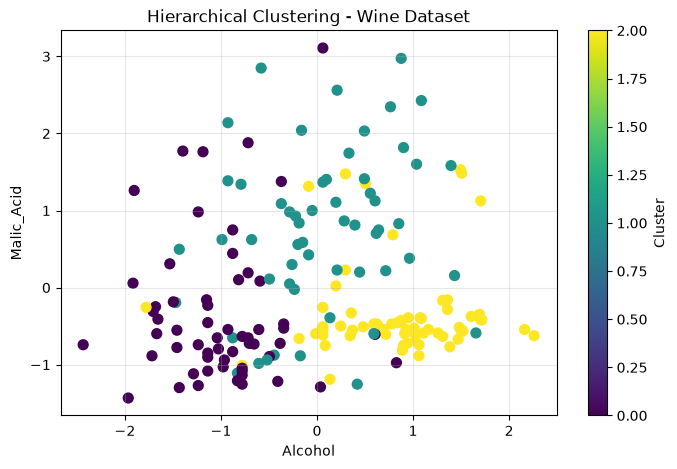

In [18]:
plt.figure(figsize=(8, 5))

plt.scatter(
    X_scaled[:, 0],
    X_scaled[:, 1],
    c=y_clusters,
    cmap="viridis",
    s=50
)

plt.xlabel(wine.columns[0])
plt.ylabel(wine.columns[1])
plt.title("Hierarchical Clustering - Wine Dataset")
plt.colorbar(label="Cluster")
plt.grid(alpha=0.3)

plt.show()

In [13]:
results = []

for k in range(2, 11):

    model = AgglomerativeClustering(
        n_clusters=k,
        linkage="ward"
    )

    labels = model.fit_predict(X_scaled)

    score = silhouette_score(X_scaled, labels)

    results.append({
        "K": k,
        "Silhouette Score": score
    })

results_df = pd.DataFrame(results)

display(results_df.round(4))

,K,Silhouette Score
0,2,0.2670
1,3,0.2774
2,4,0.2258
3,5,0.1867
4,6,0.1797
5,7,0.1869
6,8,0.1883
7,9,0.1917
8,10,0.1986


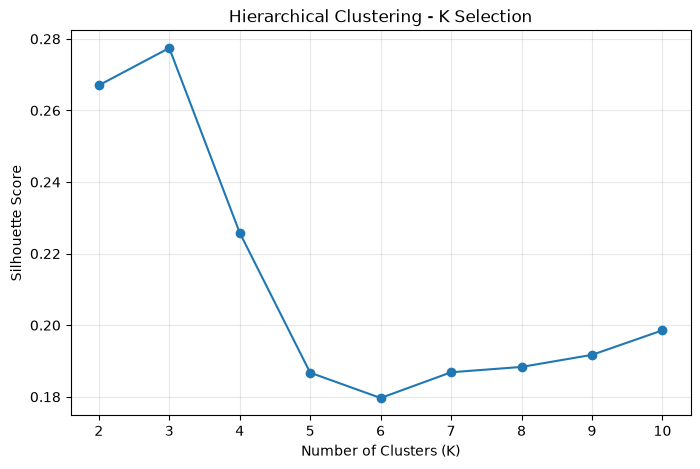

In [14]:
plt.figure(figsize=(8, 5))

plt.plot(
    results_df["K"],
    results_df["Silhouette Score"],
    marker="o"
)

plt.xlabel("Number of Clusters (K)")
plt.ylabel("Silhouette Score")
plt.title("Hierarchical Clustering - K Selection")

plt.xticks(range(2, 11))
plt.grid(alpha=0.3)

plt.show()

In [16]:

joblib.dump(hierarchical_model, "hierarchical_model.pkl")

joblib.dump(scaler, "hierarchical_scaler.pkl")

print("Model and scaler saved successfully!")

Model and scaler saved successfully!
